# 03 — Model training, tracking and selection

Executed after `02_data_pipeline.ipynb`. For each of the three models it:

1. tunes hyperparameters on the **training set** with stratified cross-validation (preprocessing is inside the pipeline, so there is no leakage between folds);
2. picks the decision threshold that maximises F1 on the **validation set**;
3. logs parameters, metrics, figures and the model to **MLflow**.

Then it selects the final model **using validation results only**, explains it (SHAP), and evaluates it **once** on the test set.

| Artifact | Purpose |
|---|---|
| `models/model.joblib` | selected model (preprocessing + classifier in one pipeline) |
| `models/model_metadata.json` | model name, version, threshold, metrics, MLflow run id — read by the API and dashboard |
| `models/candidates/*.joblib` | the three tuned candidates |
| `reports/model_comparison.csv` | validation metrics of the three models |
| `reports/test_metrics.json` | final test metrics of the selected model |
| `reports/shap_top_features.csv` | global feature importance of the selected model |
| `mlflow.db`, `mlartifacts/` | local MLflow tracking store (`mlflow ui --backend-store-uri sqlite:///mlflow.db`) |

In [14]:
import json
import os
import subprocess
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import ParameterGrid, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110


def find_root(start=None):
    """Project root = first parent folder containing requirements.txt (or a Makefile)."""
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if any((cand / marker).exists() for marker in ("requirements.txt", "Makefile")):
            return cand
    return p


ROOT = find_root()
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for d in (MODELS_DIR / "candidates", FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
QUICK = os.environ.get("CHURN_QUICK") == "1"      # tiny search, used by CI smoke tests
N_ITER = 3 if QUICK else 25                       # random-search candidates per model
CV_FOLDS = 3 if QUICK else 5
RUN_TAG = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")   # groups the runs of one execution
print(f"Project root: {ROOT} | quick mode: {QUICK} | run tag: {RUN_TAG}")

Project root: C:\Users\lenovo\Desktop\churn-mlops | quick mode: False | run tag: 20261127-130048


## 1. MLflow setup

Local store by default (SQLite file + `mlartifacts/` folder). Set the `MLFLOW_TRACKING_URI` environment variable to use a remote server instead.

In [15]:
EXPERIMENT_NAME = "churn-prediction"
REMOTE = "MLFLOW_TRACKING_URI" in os.environ
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
mlflow.set_tracking_uri(TRACKING_URI)

if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME,
                             artifact_location=None if REMOTE else (ROOT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()


def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT,
                                       stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return "unknown"


GIT_COMMIT = git_commit()
print("Tracking URI:", TRACKING_URI, "| git commit:", GIT_COMMIT)

Tracking URI: sqlite:///C:/Users/lenovo/Desktop/churn-mlops/mlflow.db | git commit: df72ff6


## 2. Load training and validation data

The **test set is deliberately not loaded here**. It is read once, in section 8.

In [16]:
cfg = json.loads((MODELS_DIR / "feature_config.json").read_text())
FEATURES, TARGET, ID_COL = cfg["features"], cfg["target"], cfg["id_col"]

forbidden = {c for cols in cfg["excluded_columns"].values() for c in cols}
assert not forbidden & set(FEATURES), "Leaky/excluded column found in FEATURES"

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "val.csv")
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]

print(f"train: {X_train.shape} (churn {y_train.mean():.1%}) | val: {X_val.shape} (churn {y_val.mean():.1%})")

# Unfitted copy of the preprocessing built in notebook 02 -> a single source of truth
base_preprocessor = clone(joblib.load(MODELS_DIR / "preprocessor.joblib"))


def make_pipeline(estimator):
    return Pipeline([("preprocessor", clone(base_preprocessor)), ("model", estimator)])

train: (4930, 18) (churn 26.5%) | val: (1056, 18) (churn 26.5%)


## 3. Helper functions

**About class imbalance:** about 26% of customers churn. Instead of re-weighting classes (which distorts predicted probabilities), the models are trained normally and the **decision threshold is tuned on the validation set**. The probabilities stay meaningful for the "predicted risk" shown in the dashboard.

In [17]:
def best_f1_threshold(y_true, proba):
    """Threshold that maximises F1 (to be chosen on validation data only)."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, proba)),
        "pr_auc": float(average_precision_score(y_true, proba)),
    }


def feature_importance(pipe):
    """Signed coefficients for logistic regression, impurity importances for tree models."""
    names = pipe.named_steps["preprocessor"].get_feature_names_out()
    est = pipe.named_steps["model"]
    values = est.coef_[0] if hasattr(est, "coef_") else est.feature_importances_
    kind = "coefficient" if hasattr(est, "coef_") else "importance"
    return pd.DataFrame({"feature": names, kind: values}).sort_values(kind, key=np.abs, ascending=False)


def plot_confusion(y_true, proba, threshold, title):
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ConfusionMatrixDisplay.from_predictions(y_true, (proba >= threshold).astype(int), ax=ax,
                                            display_labels=["Stayed", "Churned"], colorbar=False, cmap="Blues")
    ax.set_title(title)
    fig.tight_layout()
    return fig


def plot_importance(imp, title, top=15):
    col = imp.columns[1]
    top_df = imp.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.barh(top_df["feature"], top_df[col], color="#4c72b0")
    ax.set_title(title)
    fig.tight_layout()
    return fig


def log_sklearn_model(pipe, example):
    """MLflow 3 uses `name=`, MLflow 2 uses `artifact_path=`.
    cloudpickle: MLflow 3's default (skops) rejects numpy types contained in our pipeline."""
    try:
        mlflow.sklearn.log_model(pipe, name="model", input_example=example, serialization_format="cloudpickle")
    except TypeError:
        mlflow.sklearn.log_model(pipe, artifact_path="model", input_example=example,
                                 serialization_format="cloudpickle")


def to_jsonable(o):
    return o.item() if hasattr(o, "item") else str(o)

## 4. Candidate models and search spaces

| Model | Role |
|---|---|
| Logistic Regression | interpretable baseline |
| Random Forest | many decorrelated trees, captures non-linear interactions |
| Gradient Boosting | trees built sequentially, each correcting the previous errors |

Tuning is a random search scored by cross-validated ROC-AUC on the training set only.

In [18]:
CANDIDATES = {
    "Logistic Regression": {
        "estimator": LogisticRegression(max_iter=2000),
        "space": {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=SEED, n_jobs=-1),
        "space": {
            "n_estimators": [200, 300, 500],
            "max_depth": [None, 6, 10, 15],
            "min_samples_leaf": [1, 3, 5, 10],
            "max_features": ["sqrt", 0.3],
        },
    },
    "Gradient Boosting": {
        "estimator": GradientBoostingClassifier(random_state=SEED),
        "space": {
            "n_estimators": [100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
            "max_depth": [2, 3, 4],
            "subsample": [0.7, 0.85, 1.0],
            "min_samples_leaf": [1, 5, 10, 20],
        },
    },
}
COMPLEXITY_ORDER = list(CANDIDATES)   # used as tie-break when models perform alike

## 5. Train, tune and log each model

In [19]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
results = {}

for name, spec in CANDIDATES.items():
    print(f"\n=== {name} ===")
    space = {f"model__{k}": v for k, v in spec["space"].items()}
    n_iter = min(N_ITER, len(ParameterGrid(space)))
    search = RandomizedSearchCV(make_pipeline(spec["estimator"]), space, n_iter=n_iter, scoring="roc_auc",
                                cv=cv, n_jobs=-1, random_state=SEED, refit=True)

    with mlflow.start_run(run_name=name) as run:
        mlflow.set_tags({"model_family": name, "pipeline_run": RUN_TAG, "git_commit": GIT_COMMIT,
                         "selected": "false"})

        t0 = time.time()
        search.fit(X_train, y_train)
        fit_seconds = time.time() - t0
        pipe = search.best_estimator_

        val_proba = pipe.predict_proba(X_val)[:, 1]
        threshold = best_f1_threshold(y_val, val_proba)
        val_metrics = evaluate(y_val, val_proba, threshold)
        val_at_05 = evaluate(y_val, val_proba, 0.5)
        train_auc = float(roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]))
        best_idx = search.best_index_
        cv_mean = float(search.cv_results_["mean_test_score"][best_idx])
        cv_std = float(search.cv_results_["std_test_score"][best_idx])
        best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}

        # ---- MLflow logging
        mlflow.log_params({**best_params, "n_iter": n_iter, "cv_folds": CV_FOLDS, "seed": SEED,
                           "n_features": len(FEATURES), "train_rows": len(X_train)})
        mlflow.log_metrics({
            **{f"val_{k}": v for k, v in val_metrics.items()},
            "val_threshold": threshold,
            "val_f1_at_0.5": val_at_05["f1"],
            "cv_roc_auc_mean": cv_mean, "cv_roc_auc_std": cv_std,
            "train_roc_auc": train_auc, "fit_seconds": fit_seconds,
        })
        imp = feature_importance(pipe)
        fig_cm = plot_confusion(y_val, val_proba, threshold, f"{name} (validation)")
        fig_imp = plot_importance(imp, f"{name}: top features")
        mlflow.log_figure(fig_cm, "confusion_matrix_validation.png")
        mlflow.log_figure(fig_imp, "feature_importance.png")
        plt.close(fig_cm)
        plt.close(fig_imp)
        log_sklearn_model(pipe, X_train.head(5))
        run_id = run.info.run_id

    joblib.dump(pipe, MODELS_DIR / "candidates" / f"{name.lower().replace(' ', '_')}.joblib")
    results[name] = {"pipeline": pipe, "run_id": run_id, "threshold": threshold, "val_proba": val_proba,
                     "val": val_metrics, "val_at_05": val_at_05, "cv_mean": cv_mean, "cv_std": cv_std,
                     "train_auc": train_auc, "fit_seconds": fit_seconds, "best_params": best_params}
    print(f"best params: {best_params}")
    print(f"CV AUC {cv_mean:.3f} (+/- {cv_std:.3f}) | train AUC {train_auc:.3f} | val AUC {val_metrics['roc_auc']:.3f} "
          f"| val F1 {val_metrics['f1']:.3f} @ threshold {threshold:.2f} | {fit_seconds:.0f}s")


=== Logistic Regression ===


2026/11/27 14:08:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\lenovo\Desktop\churn-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing va

best params: {'C': 100}
CV AUC 0.858 (+/- 0.010) | train AUC 0.862 | val AUC 0.849 | val F1 0.635 @ threshold 0.52 | 170s

=== Random Forest ===


2026/11/27 14:13:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\lenovo\Desktop\churn-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing va

best params: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 10}
CV AUC 0.859 (+/- 0.009) | train AUC 0.914 | val AUC 0.851 | val F1 0.656 @ threshold 0.31 | 119s

=== Gradient Boosting ===


2026/11/27 14:18:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\lenovo\Desktop\churn-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing va

best params: {'subsample': 0.85, 'n_estimators': 200, 'min_samples_leaf': 5, 'max_depth': 2, 'learning_rate': 0.05}
CV AUC 0.863 (+/- 0.010) | train AUC 0.878 | val AUC 0.854 | val F1 0.649 @ threshold 0.37 | 64s


## 6. Compare the models on the validation set

- **Precision**: among customers flagged as likely to leave, how many actually left?
- **Recall**: among customers who left, how many did the model identify?
- **F1**: balance between precision and recall.
- **ROC-AUC**: how well the model ranks churners above non-churners (independent of the threshold).

Precision, recall and F1 use each model's own validation-tuned threshold. A large gap between train AUC and validation AUC signals overfitting.

In [20]:
comparison = pd.DataFrame({
    name: {
        "precision": r["val"]["precision"], "recall": r["val"]["recall"], "f1": r["val"]["f1"],
        "roc_auc": r["val"]["roc_auc"], "pr_auc": r["val"]["pr_auc"], "threshold": r["threshold"],
        "f1_at_0.5": r["val_at_05"]["f1"], "cv_roc_auc": r["cv_mean"], "train_roc_auc": r["train_auc"],
        "fit_seconds": r["fit_seconds"],
    } for name, r in results.items()
}).T
comparison.index.name = "model"
comparison = comparison.rename(columns={"roc_auc": "val_roc_auc", "precision": "val_precision",
                                        "recall": "val_recall", "f1": "val_f1", "pr_auc": "val_pr_auc"})
comparison.round(3).to_csv(REPORTS_DIR / "model_comparison.csv")
display(comparison.round(3))

,val_precision,val_recall,val_f1,val_roc_auc,val_pr_auc,threshold,f1_at_0.5,cv_roc_auc,train_roc_auc,fit_seconds
model,,,,,,,,,,
Logistic Regression,0.653,0.618,0.635,0.849,0.635,0.518,0.630,0.858,0.862,169.527
Random Forest,0.546,0.821,0.656,0.851,0.642,0.313,0.585,0.859,0.914,119.277
Gradient Boosting,0.574,0.746,0.649,0.854,0.655,0.374,0.597,0.863,0.878,64.157


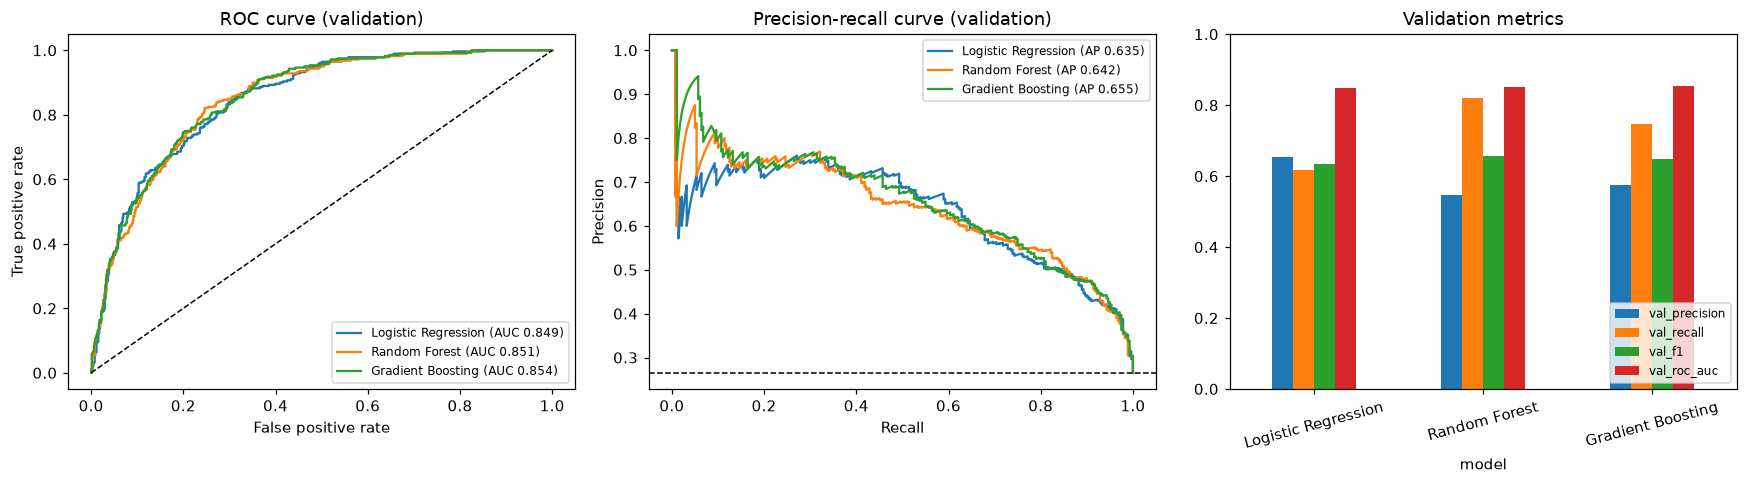

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_val, r["val_proba"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {r['val']['roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_val, r["val_proba"])
    axes[1].plot(rec, prec, label=f"{name} (AP {r['val']['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve (validation)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_val.mean(), color="k", ls="--", lw=1)
axes[1].set(title="Precision-recall curve (validation)", xlabel="Recall", ylabel="Precision")
for ax in axes[:2]:
    ax.legend(loc="best", fontsize=8)

metric_cols = ["val_precision", "val_recall", "val_f1", "val_roc_auc"]
comparison[metric_cols].plot.bar(ax=axes[2], rot=15)
axes[2].set(title="Validation metrics", ylim=(0, 1))
axes[2].legend(fontsize=8, loc="lower right")

fig.tight_layout()
fig.savefig(FIG_DIR / "07_model_comparison.png", bbox_inches="tight")
plt.show()

## 7. Select the final model (validation results only)

Rule, fixed **before** looking at the test set: pick the model with the highest validation ROC-AUC. If several models are within `0.005` AUC of the best, prefer the simplest one (Logistic Regression < Random Forest < Gradient Boosting) — a tie in performance is not worth extra complexity.

In [22]:
AUC_TOLERANCE = 0.005
best_auc = comparison["val_roc_auc"].max()
eligible = comparison.index[comparison["val_roc_auc"] >= best_auc - AUC_TOLERANCE].tolist()
selected_name = min(eligible, key=COMPLEXITY_ORDER.index)

selected = results[selected_name]
final_pipe = selected["pipeline"]
THRESHOLD = selected["threshold"]

for name, r in results.items():
    client.set_tag(r["run_id"], "selected", "true" if name == selected_name else "false")

print(f"Best validation ROC-AUC: {best_auc:.3f} | within tolerance: {eligible}")
print(f"Selected model: {selected_name} | decision threshold: {THRESHOLD:.3f}")

Best validation ROC-AUC: 0.854 | within tolerance: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
Selected model: Logistic Regression | decision threshold: 0.518


## 8. Explain the selected model (SHAP)

SHAP values show how much each feature pushes a customer's predicted churn probability up or down. Computed on a validation sample, never on the test set.

PermutationExplainer explainer: 301it [00:16,  7.75it/s]                         


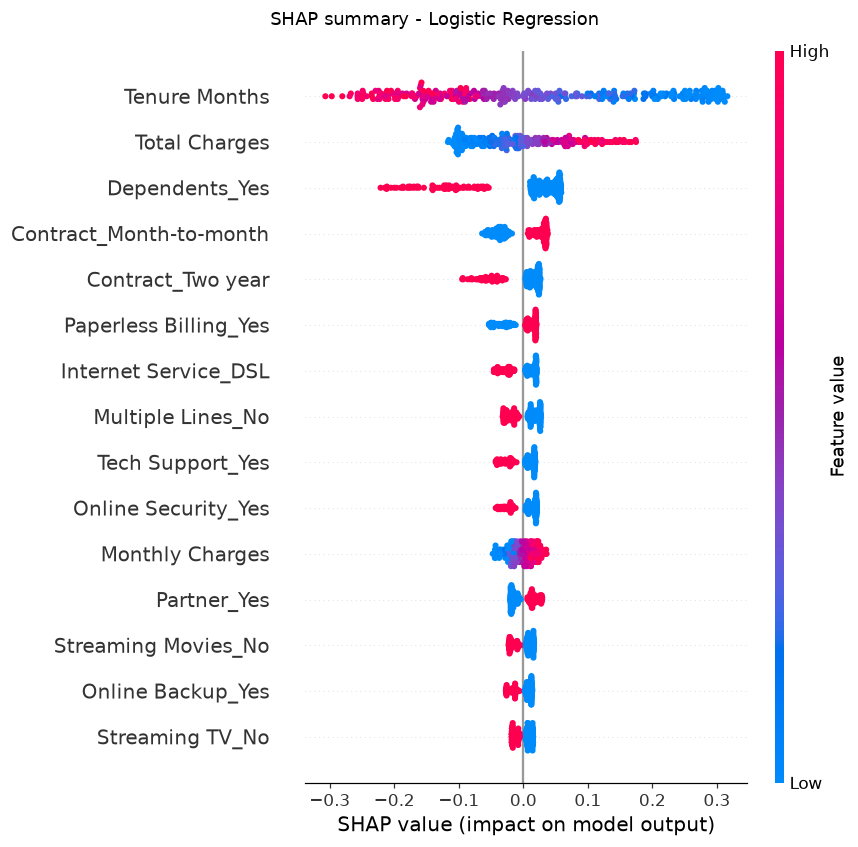

Explanation method: shap


,feature,mean_abs_shap,method
0,Tenure Months,0.1489,shap
2,Total Charges,0.0633,shap
5,Dependents_Yes,0.0599,shap
31,Contract_Month-to-month,0.0333,shap
33,Contract_Two year,0.0258,shap
34,Paperless Billing_Yes,0.0208,shap
10,Internet Service_DSL,0.0198,shap
7,Multiple Lines_No,0.0198,shap
24,Tech Support_Yes,0.0175,shap
15,Online Security_Yes,0.0174,shap


In [23]:
fitted_pre = final_pipe.named_steps["preprocessor"]
estimator = final_pipe.named_steps["model"]
feature_names = list(fitted_pre.get_feature_names_out())

Xt_train = pd.DataFrame(fitted_pre.transform(X_train), columns=feature_names)
Xt_val = pd.DataFrame(fitted_pre.transform(X_val), columns=feature_names)

n_explain, n_background = (40, 30) if QUICK else (300, 100)
sample = Xt_val.sample(min(n_explain, len(Xt_val)), random_state=SEED)
background = Xt_train.sample(min(n_background, len(Xt_train)), random_state=SEED)

explain_fig = None
try:
    import shap

    def predict_churn(data):
        return estimator.predict_proba(pd.DataFrame(data, columns=feature_names))[:, 1]

    explainer = shap.Explainer(predict_churn, background)
    shap_values = explainer(sample).values

    top_features = (pd.DataFrame({"feature": feature_names, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
                    .sort_values("mean_abs_shap", ascending=False))
    plt.figure()
    shap.summary_plot(shap_values, sample, show=False, max_display=15)
    explain_fig = plt.gcf()
    explain_fig.suptitle(f"SHAP summary - {selected_name}", y=1.02)
    method = "shap"
except Exception as exc:   # explanations must never break the training pipeline
    print(f"WARNING: SHAP failed ({type(exc).__name__}: {exc}). Falling back to permutation importance.")
    perm = permutation_importance(final_pipe, X_val, y_val, scoring="roc_auc", n_repeats=5, random_state=SEED)
    top_features = (pd.DataFrame({"feature": FEATURES, "mean_abs_shap": perm.importances_mean})
                    .sort_values("mean_abs_shap", ascending=False))
    method = "permutation_importance"

top_features["method"] = method
top_features.to_csv(REPORTS_DIR / "shap_top_features.csv", index=False)
if explain_fig is not None:
    explain_fig.savefig(FIG_DIR / "08_shap_summary.png", bbox_inches="tight")
    plt.show()
print(f"Explanation method: {method}")
display(top_features.head(10).round(4))

## 9. Final evaluation on the test set (once)

This is the only cell that reads `test.csv`. The threshold comes from the validation set. **Do not go back and change the model after looking at these numbers** — that would turn the test set into a second validation set.

Logistic Regression - TEST set (threshold 0.518)
   precision: 0.691
      recall: 0.541
          f1: 0.607
     roc_auc: 0.859
      pr_auc: 0.688

              precision    recall  f1-score   support

      Stayed       0.85      0.91      0.88       776
     Churned       0.69      0.54      0.61       281

    accuracy                           0.81      1057
   macro avg       0.77      0.73      0.74      1057
weighted avg       0.80      0.81      0.81      1057



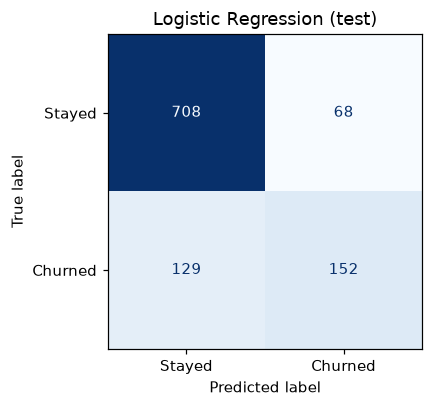

249

In [24]:
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")
X_test, y_test = test_df[FEATURES], test_df[TARGET]

test_proba = final_pipe.predict_proba(X_test)[:, 1]
test_metrics = evaluate(y_test, test_proba, THRESHOLD)

print(f"{selected_name} - TEST set (threshold {THRESHOLD:.3f})")
for k, v in test_metrics.items():
    print(f"  {k:>10}: {v:.3f}")
print()
print(classification_report(y_test, (test_proba >= THRESHOLD).astype(int), target_names=["Stayed", "Churned"]))

fig_test_cm = plot_confusion(y_test, test_proba, THRESHOLD, f"{selected_name} (test)")
fig_test_cm.savefig(FIG_DIR / "09_confusion_matrix_test.png", bbox_inches="tight")
plt.show()

(REPORTS_DIR / "test_metrics.json").write_text(json.dumps(
    {"model": selected_name, "threshold": THRESHOLD, "n_test": int(len(y_test)), **test_metrics}, indent=2))

## 10. Save the final model and log everything to MLflow

In [25]:
trained_at = datetime.now(timezone.utc).isoformat(timespec="seconds")

with mlflow.start_run(run_id=selected["run_id"]):      # re-open the selected model's run
    mlflow.set_tag("selected", "true")
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig_test_cm, "confusion_matrix_test.png")
    if explain_fig is not None:
        mlflow.log_figure(explain_fig, "shap_summary.png")
    for path in (REPORTS_DIR / "model_comparison.csv", REPORTS_DIR / "shap_top_features.csv",
                 REPORTS_DIR / "test_metrics.json", MODELS_DIR / "feature_config.json",
                 REPORTS_DIR / "data_validation.json", FIG_DIR / "07_model_comparison.png"):
        if path.exists():
            mlflow.log_artifact(str(path))
plt.close("all")

joblib.dump(final_pipe, MODELS_DIR / "model.joblib")

metadata = {
    "model_name": selected_name,
    "model_version": RUN_TAG,
    "trained_at": trained_at,
    "decision_threshold": THRESHOLD,
    "target": TARGET,
    "features": FEATURES,
    "best_params": selected["best_params"],
    "metrics": {"validation": selected["val"], "test": test_metrics},
    "selection_rule": f"highest validation ROC-AUC; ties within {AUC_TOLERANCE} go to the simpler model",
    "training_rows": int(len(X_train)),
    "train_churn_rate": round(float(y_train.mean()), 4),
    "mlflow": {"tracking_uri": TRACKING_URI, "experiment": EXPERIMENT_NAME, "run_id": selected["run_id"]},
    "git_commit": GIT_COMMIT,
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2, default=to_jsonable))
print(f"Saved models/model.joblib (version {RUN_TAG}) and models/model_metadata.json")

Saved models/model.joblib (version 20261127-130048) and models/model_metadata.json


In [26]:
print("Training pipeline finished. Artifacts:")
for p in [MODELS_DIR / "model.joblib", MODELS_DIR / "model_metadata.json", REPORTS_DIR / "model_comparison.csv",
          REPORTS_DIR / "test_metrics.json", REPORTS_DIR / "shap_top_features.csv"]:
    print(" -", p.relative_to(ROOT))
print("\nBrowse the experiments with:  mlflow ui --backend-store-uri", f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")

Training pipeline finished. Artifacts:
 - models\model.joblib
 - models\model_metadata.json
 - reports\model_comparison.csv
 - reports\test_metrics.json
 - reports\shap_top_features.csv

Browse the experiments with:  mlflow ui --backend-store-uri sqlite:///C:/Users/lenovo/Desktop/churn-mlops/mlflow.db
